# 02 · Building the recommender with Surprise

We use [Surprise](https://surpriselib.com), a Python library for **collaborative filtering**: learning "customers like you scored this highly" from a customer × item × score table.

We compare four algorithms:
- **NormalPredictor** — random guesses (a floor to beat)
- **BaselineOnly** — "this customer scores things high/low on average" + "this item is generally popular"
- **KNNBasic (item-based)** — "items similar to ones you liked"
- **SVD** — matrix factorisation: learns hidden "tastes" for each customer and item (made famous by the Netflix Prize)

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.recsys import *

plt.rcParams["figure.figsize"] = (8, 4.5)
TEAL, CORAL, GREY = "#1f6f8b", "#e07a5f", "#9aa5ab"

In [2]:
from surprise import SVD, BaselineOnly, KNNBasic, NormalPredictor
from surprise.model_selection import cross_validate, train_test_split, GridSearchCV

customers, catalogue, engagement = load_tables()
data = to_surprise(engagement)

## 1. How accurately does each model predict the score? (5-fold cross-validation)

- **RMSE / MAE**: average error when predicting a 1–5 score. Lower is better.
- **5-fold CV**: split the data 5 ways, train on 4, test on 1, repeat — a fairer estimate than one split.

In [3]:
np.random.seed(42)
models = {
    "Random (NormalPredictor)": NormalPredictor(),
    "BaselineOnly": BaselineOnly(verbose=False),
    "KNN (item-based)": KNNBasic(sim_options={"name": "pearson_baseline", "user_based": False}, verbose=False),
    "SVD": SVD(random_state=42),
}
rows = []
for name, algo in models.items():
    cv = cross_validate(algo, data, measures=["RMSE", "MAE"], cv=5, verbose=False)
    rows.append({"model": name, "RMSE": cv["test_rmse"].mean(), "MAE": cv["test_mae"].mean()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,RMSE,MAE
model,,
Random (NormalPredictor),1.459,1.178
BaselineOnly,0.978,0.794
KNN (item-based),1.128,0.888
SVD,0.925,0.748


## 2. Tune SVD

`n_factors` = how many hidden tastes, `reg_all` = regularisation (stops memorising), `lr_all` = learning rate, `n_epochs` = passes over the data.

In [4]:
grid = GridSearchCV(SVD, {"n_factors": [10, 30, 50], "n_epochs": [20, 40],
                          "lr_all": [0.005, 0.01], "reg_all": [0.02, 0.1],
                          "random_state": [42]},   # fixed seed so results are reproducible
                    measures=["rmse"], cv=3, n_jobs=-1)
grid.fit(data)
best_params = grid.best_params["rmse"]
print("Best RMSE:", round(grid.best_score["rmse"], 3)); print("Best params:", best_params)

Best RMSE: 0.932
Best params: {'n_factors': 10, 'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.02, 'random_state': 42}


> Why is this RMSE not lower than the SVD row in the table above? The grid search uses **3 folds** (for speed) and the table uses **5**, so the numbers aren't directly comparable. The grid's job is to pick *between* parameter settings, which it does.

## 3. Does it recommend the right things? (precision@5 and recall@5)

RMSE measures score prediction, but the app only shows **5 items**. So we also check ranking:

- hold back 20% of engagement records as a test set
- for each customer, rank every item they haven't seen and take the top 5
- an item is **relevant** if the customer actually scored it 4–5 in the test set
- **precision@5**: of the 5 shown, how many were relevant?
- **recall@5**: of the relevant ones, how many made the top 5?

In [5]:
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
items = catalogue["item_id"].tolist()
np.random.seed(42)   # NormalPredictor uses numpy's random numbers
final_models = {"Random (NormalPredictor)": NormalPredictor(), "BaselineOnly": BaselineOnly(verbose=False),
                "SVD (tuned)": SVD(**best_params)}
rank_rows = []
for name, algo in final_models.items():
    algo.fit(trainset)
    p, r = precision_recall_at_k(top_n(rank_unseen(algo, trainset, items)), testset)
    rank_rows.append({"model": name, "precision@5": p, "recall@5": r})
rank_table = pd.DataFrame(rank_rows).set_index("model").round(3)
rank_table

,precision@5,recall@5
model,,
Random (NormalPredictor),0.056,0.213
BaselineOnly,0.125,0.480
SVD (tuned),0.165,0.617


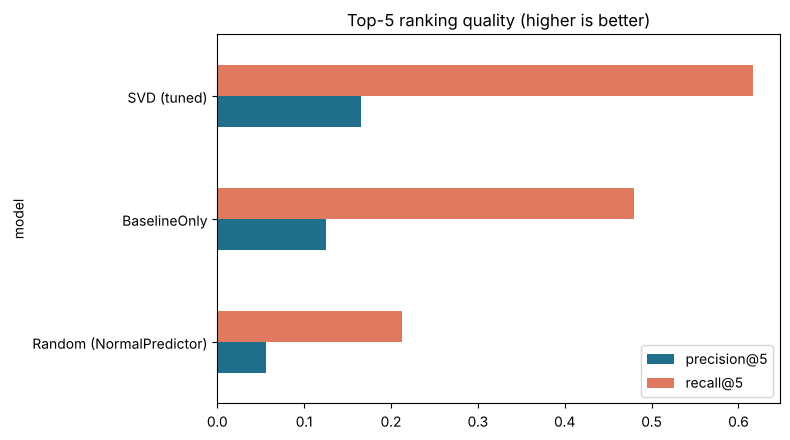

In [6]:
rank_table.plot.barh(color=[TEAL, CORAL]); plt.title("Top-5 ranking quality (higher is better)")
plt.tight_layout(); plt.savefig("../images/ranking_quality.png", dpi=120, bbox_inches="tight"); plt.show()

In [7]:
import json, os
os.makedirs("../results", exist_ok=True)
json.dump({"best_params": best_params, "cv": cv_table.reset_index().to_dict("records"),
           "ranking": rank_table.reset_index().to_dict("records")}, open("../results/model_selection.json", "w"), indent=2)

## Summary
- Tuned **SVD** gives the best ranking, so it becomes our recommender.
- Note what we optimised: **engagement**. Nothing so far asks whether a recommendation is *good for the customer*. Notebook 03 checks exactly that.